# Auditoria inicial da base Bank Marketing

**Projeto:** Efeito de degradações controladas na qualidade dos dados de treinamento sobre o desempenho preditivo e a estabilidade de explicações SHAP: um estudo experimental com dados tabulares.

Este notebook registra a origem, a integridade e as características iniciais da base escolhida. Ele não executa o experimento principal nem apresenta resultados finais do estudo.

## tl;dr

- A base auditada é o arquivo oficial `bank-full.csv`, preservado sem modificações.
- A verificação cobre dimensões, esquema, ausências, duplicidades, categorias `unknown`, distribuição do alvo e faixas numéricas.
- `duration` é sinalizada como risco de vazamento para um cenário de decisão anterior à ligação.
- Os números exibidos abaixo são observações reproduzíveis da base, não resultados de modelos.

## Contexto e métodos

### Premissas principais

1. A unidade observacional é um registro de contato de campanha, e não necessariamente um cliente único.
2. O alvo `y` indica contratação (`yes`) ou não contratação (`no`) de depósito a prazo.
3. A documentação oficial informa ausência de valores nulos, mas a base contém a categoria textual `unknown` em alguns atributos; ela será quantificada separadamente.
4. A auditoria não altera o arquivo original e registra seu hash SHA-256.
5. Fonte: UCI Machine Learning Repository, DOI [10.24432/C5K306](https://doi.org/10.24432/C5K306), licença CC BY 4.0.

In [1]:
from pathlib import Path
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

plt.style.use('seaborn-v0_8-whitegrid')
PALETTE = {'blue': '#3267A8', 'gold': '#C38C2C', 'gray': '#5F6B76', 'light': '#D8E3F0'}

ROOT = Path.cwd()
DATA_PATH = ROOT / 'dados' / 'brutos' / 'bank_marketing_uci' / 'bank' / 'bank-full.csv'
RESULTS_DIR = ROOT / 'resultados'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

assert DATA_PATH.exists(), f'Arquivo não encontrado: {DATA_PATH}'
DATA_PATH

WindowsPath('<PROJECT_ROOT>/experimentos/dados/brutos/bank_marketing_uci/bank/bank-full.csv')

## Dados

In [2]:
def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

df = pd.read_csv(DATA_PATH, sep=';')
file_hash = sha256(DATA_PATH)

source_receipt = pd.DataFrame([{
    'fonte': 'UCI Machine Learning Repository — Bank Marketing',
    'url': 'https://archive.ics.uci.edu/dataset/222/bank%2Bmarketing',
    'doi': '10.24432/C5K306',
    'licenca': 'CC BY 4.0',
    'arquivo': str(DATA_PATH),
    'sha256': file_hash,
    'linhas': len(df),
    'colunas': df.shape[1],
}])
display(source_receipt.T)
display(df.head())

,0
fonte,UCI Machine Learning Repository — Bank Marketing
url,https://archive.ics.uci.edu/dataset/222/bank%2...
doi,10.24432/C5K306
licenca,CC BY 4.0
arquivo,<PROJECT_ROOT>\experimentos\dado...
sha256,d1513ec63b385506f7cfce9f2c5caa9fe99e7ba4e8c3fa...
linhas,45211
colunas,17


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
descriptions = {
    'age': ('numérico', 'idade do cliente'),
    'job': ('categórico', 'tipo de ocupação'),
    'marital': ('categórico', 'estado civil'),
    'education': ('categórico', 'nível de escolaridade'),
    'default': ('binário', 'possui crédito em inadimplência'),
    'balance': ('numérico', 'saldo médio anual, em euros'),
    'housing': ('binário', 'possui financiamento habitacional'),
    'loan': ('binário', 'possui empréstimo pessoal'),
    'contact': ('categórico', 'tipo de comunicação do contato'),
    'day': ('numérico', 'dia do mês do último contato'),
    'month': ('categórico', 'mês do último contato'),
    'duration': ('numérico', 'duração do último contato, em segundos'),
    'campaign': ('numérico', 'contatos nesta campanha, incluindo o último'),
    'pdays': ('numérico', 'dias desde contato anterior; -1 indica sem contato anterior'),
    'previous': ('numérico', 'contatos antes da campanha atual'),
    'poutcome': ('categórico', 'resultado da campanha anterior'),
    'y': ('alvo binário', 'contratação do depósito a prazo'),
}

dictionary = pd.DataFrame([
    {
        'variavel': column,
        'papel': 'alvo' if column == 'y' else 'atributo preditivo',
        'tipo_documentado': descriptions[column][0],
        'tipo_pandas': str(df[column].dtype),
        'descricao': descriptions[column][1],
        'valores_distintos': int(df[column].nunique(dropna=False)),
    }
    for column in df.columns
])
dictionary.to_csv(RESULTS_DIR / 'dicionario_dados_bank_marketing.csv', index=False, encoding='utf-8-sig')
display(dictionary)

,variavel,papel,tipo_documentado,tipo_pandas,descricao,valores_distintos
0,age,atributo preditivo,numérico,int64,idade do cliente,77
1,job,atributo preditivo,categórico,object,tipo de ocupação,12
2,marital,atributo preditivo,categórico,object,estado civil,3
3,education,atributo preditivo,categórico,object,nível de escolaridade,4
4,default,atributo preditivo,binário,object,possui crédito em inadimplência,2
5,balance,atributo preditivo,numérico,int64,"saldo médio anual, em euros",7168
6,housing,atributo preditivo,binário,object,possui financiamento habitacional,2
7,loan,atributo preditivo,binário,object,possui empréstimo pessoal,2
8,contact,atributo preditivo,categórico,object,tipo de comunicação do contato,3
9,day,atributo preditivo,numérico,int64,dia do mês do último contato,31


## Resultados

In [4]:
duplicate_rows = int(df.duplicated().sum())
null_counts = df.isna().sum().sort_values(ascending=False)
unknown_counts = pd.Series({
    column: int(df[column].astype(str).str.lower().eq('unknown').sum())
    for column in df.select_dtypes(include='object').columns
}).sort_values(ascending=False)

quality_summary = pd.DataFrame([
    {'verificacao': 'linhas', 'valor': len(df), 'observacao': 'registros no arquivo'},
    {'verificacao': 'colunas', 'valor': df.shape[1], 'observacao': '16 atributos + alvo'},
    {'verificacao': 'nulos reais', 'valor': int(df.isna().sum().sum()), 'observacao': 'NaN/None detectados pelo pandas'},
    {'verificacao': 'linhas duplicadas exatas', 'valor': duplicate_rows, 'observacao': 'duplicidade em todas as 17 colunas'},
    {'verificacao': "categorias 'unknown'", 'valor': int(unknown_counts.sum()), 'observacao': 'soma de ocorrências por coluna; não equivale a linhas únicas'},
])
display(quality_summary)
display(pd.DataFrame({'nulos': null_counts, 'unknown': unknown_counts.reindex(df.columns, fill_value=0)}))

,verificacao,valor,observacao
0,linhas,45211,registros no arquivo
1,colunas,17,16 atributos + alvo
2,nulos reais,0,NaN/None detectados pelo pandas
3,linhas duplicadas exatas,0,duplicidade em todas as 17 colunas
4,categorias 'unknown',52124,soma de ocorrências por coluna; não equivale a...


,nulos,unknown
age,0,0
job,0,288
marital,0,0
education,0,1857
default,0,0
balance,0,0
housing,0,0
loan,0,0
contact,0,13020
day,0,0


,quantidade,percentual
classe,,
no,39922,88.30152
yes,5289,11.69848


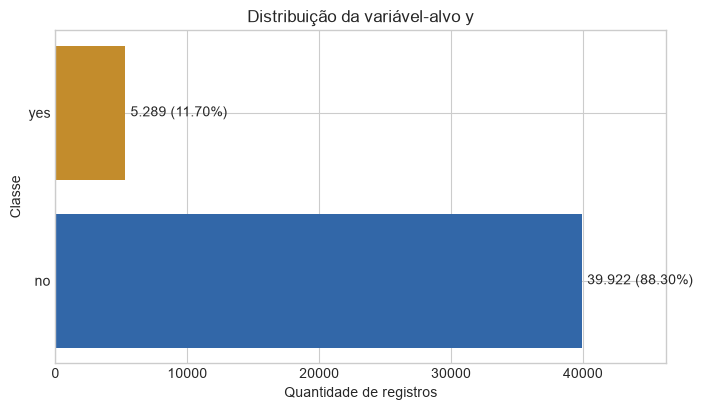

In [5]:
target_counts = df['y'].value_counts().rename_axis('classe').to_frame('quantidade')
target_counts['percentual'] = target_counts['quantidade'] / len(df) * 100
display(target_counts)

fig, ax = plt.subplots(figsize=(7.2, 4.2))
bars = ax.barh(target_counts.index, target_counts['quantidade'], color=[PALETTE['blue'], PALETTE['gold']])
ax.set_title('Distribuição da variável-alvo y')
ax.set_xlabel('Quantidade de registros')
ax.set_ylabel('Classe')
ax.set_xlim(0, target_counts['quantidade'].max() * 1.16)
for bar, (_, row) in zip(bars, target_counts.iterrows()):
    ax.text(bar.get_width() + 400, bar.get_y() + bar.get_height()/2,
            f"{int(row['quantidade']):,} ({row['percentual']:.2f}%)".replace(',', '.'),
            va='center', fontsize=10)
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'distribuicao_alvo.png', dpi=180, bbox_inches='tight')
plt.show()

,quantidade,percentual
poutcome,36959,81.747805
contact,13020,28.798301
education,1857,4.107407
job,288,0.637013


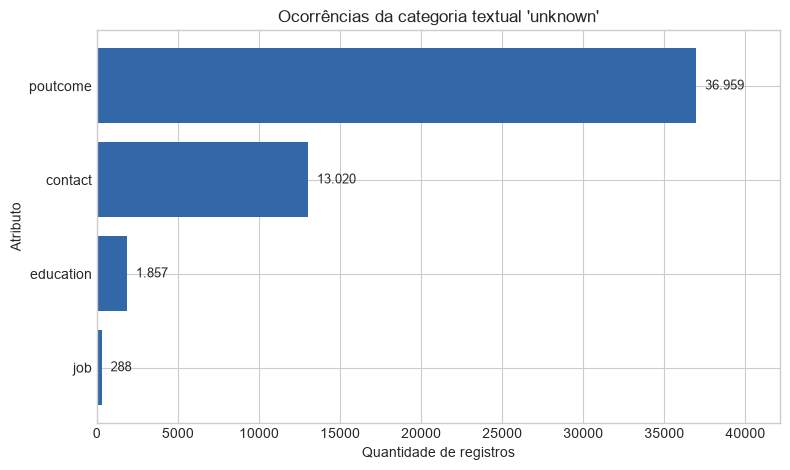

In [6]:
unknown_nonzero = unknown_counts[unknown_counts > 0].sort_values()
unknown_table = pd.DataFrame({
    'quantidade': unknown_nonzero,
    'percentual': unknown_nonzero / len(df) * 100,
})
display(unknown_table.sort_values('quantidade', ascending=False))

fig, ax = plt.subplots(figsize=(8, 4.8))
bars = ax.barh(unknown_nonzero.index, unknown_nonzero.values, color=PALETTE['blue'])
ax.set_title("Ocorrências da categoria textual 'unknown'")
ax.set_xlabel('Quantidade de registros')
ax.set_ylabel('Atributo')
ax.set_xlim(0, unknown_nonzero.max() * 1.14)
for bar, value in zip(bars, unknown_nonzero.values):
    ax.text(value + unknown_nonzero.max() * 0.015, bar.get_y() + bar.get_height()/2,
            f'{value:,}'.replace(',', '.'), va='center', fontsize=9)
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'categorias_unknown.png', dpi=180, bbox_inches='tight')
plt.show()

In [7]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
numeric_profile = df[numeric_columns].describe(percentiles=[.01, .25, .5, .75, .99]).T
display(numeric_profile)

validity_checks = pd.DataFrame([
    {'regra': 'age > 0', 'violacoes': int((df['age'] <= 0).sum())},
    {'regra': '1 <= day <= 31', 'violacoes': int((~df['day'].between(1, 31)).sum())},
    {'regra': 'duration >= 0', 'violacoes': int((df['duration'] < 0).sum())},
    {'regra': 'campaign >= 1', 'violacoes': int((df['campaign'] < 1).sum())},
    {'regra': 'pdays >= -1', 'violacoes': int((df['pdays'] < -1).sum())},
    {'regra': 'previous >= 0', 'violacoes': int((df['previous'] < 0).sum())},
    {'regra': "y em {'yes','no'}", 'violacoes': int((~df['y'].isin(['yes', 'no'])).sum())},
])
display(validity_checks)

,count,mean,std,min,1%,25%,50%,75%,99%,max
age,45211.0,40.936210,10.618762,18.0,23.0,33.0,39.0,48.0,71.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,-627.0,72.0,448.0,1428.0,13164.9,102127.0
day,45211.0,15.806419,8.322476,1.0,2.0,8.0,16.0,21.0,31.0,31.0
duration,45211.0,258.163080,257.527812,0.0,11.0,103.0,180.0,319.0,1269.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,1.0,2.0,3.0,16.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,-1.0,370.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,0.0,8.9,275.0


,regra,violacoes
0,age > 0,0
1,1 <= day <= 31,0
2,duration >= 0,0
3,campaign >= 1,0
4,pdays >= -1,0
5,previous >= 0,0
6,"y em {'yes','no'}",0


### Risco de vazamento temporal/operacional

O atributo `duration` mede a duração do último contato telefônico. Se o uso pretendido for decidir **antes** da ligação quais clientes priorizar, esse valor ainda não existe no momento da decisão. Nesse cenário, mantê-lo como preditor produz vazamento de informação. Por isso, o protocolo principal o exclui; uma análise secundária poderá mantê-lo apenas se o objetivo for explicitamente pós-contato.

In [8]:
audit_record = {
    'source': source_receipt.iloc[0].to_dict(),
    'duplicate_rows': duplicate_rows,
    'null_values': int(df.isna().sum().sum()),
    'unknown_by_column': {k: int(v) for k, v in unknown_counts.items() if v > 0},
    'target_counts': {k: int(v) for k, v in df['y'].value_counts().items()},
    'validity_rule_violations': dict(zip(validity_checks['regra'], validity_checks['violacoes'].astype(int))),
    'primary_protocol_excludes_duration': True,
}

with (RESULTS_DIR / 'auditoria_inicial.json').open('w', encoding='utf-8') as stream:
    json.dump(audit_record, stream, ensure_ascii=False, indent=2)

quality_summary.to_csv(RESULTS_DIR / 'resumo_qualidade.csv', index=False, encoding='utf-8-sig')
source_receipt.to_csv(RESULTS_DIR / 'comprovante_fonte.csv', index=False, encoding='utf-8-sig')
print('Resultados salvos em:', RESULTS_DIR.resolve())

Resultados salvos em: &lt;PROJECT_ROOT&gt;\experimentos\resultados


## Conclusões

Esta auditoria estabelece o ponto de partida do experimento. A base deve ser tratada como **documentada e reproduzível**, não como perfeitamente limpa: a ausência de `NaN` não elimina categorias `unknown`, possível repetição de registros nem riscos de uso indevido de variáveis disponíveis somente após o evento de decisão.

Próxima etapa: congelar o protocolo e executar o piloto reduzido de 9 treinamentos (Random Forest, valores ausentes, níveis de 10% e 30%, três sementes) antes da matriz completa de 390 treinamentos.